# DAY13：数据可视化与经营仪表盘

## 一、项目分析目标

通过数据可视化展示 Olist 巴西电商平台的经营情况，
从客户价值、销售趋势、商品类别和物流履约等角度进行分析。

## 二、数据准备与处理

## 三、客户价值分析

## 四、月度销售趋势分析

## 五、商品类别销售分析

## 六、物流配送与延迟率分析

## 七、分析结论

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [49]:
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

In [50]:
#导入day12的RFM数据
rfm = pd.read_csv("rfm.csv")

In [51]:
#检查rfm数据
print(rfm.head())
print(rfm.shape)
print(rfm.info())

                 customer_unique_id        last_purchase  recency  frequency  \
0  0000366f3b9a7992bf8c76cfdf3221e2  2018-05-10 10:56:27      111          1   
1  0000b849f77a49e4a4ce2b2a4ca5be3f  2018-05-07 11:11:27      114          1   
2  0000f46a3911fa3c0805444483337064  2017-03-10 21:05:03      537          1   
3  0000f6ccb0745a6a4b88665a16c9f078  2017-10-12 20:29:41      321          1   
4  0004aac84e0df4da2b147fca70cf8255  2017-11-14 19:45:42      288          1   

   monetary  R_score  F_score  M_score  RFM_score customer_segment  
0    141.90        4        1      4.0        9.0           较高价值客户  
1     27.19        4        1      1.0        6.0           较低价值客户  
2     86.22        1        1      2.0        4.0            低价值客户  
3     43.62        2        1      1.0        4.0            低价值客户  
4    196.89        2        1      4.0        7.0           中等价值客户  
(93358, 10)
<class 'pandas.DataFrame'>
RangeIndex: 93358 entries, 0 to 93357
Data columns (total 10 colum

In [52]:
rfm["last_purchase"] = pd.to_datetime(
    rfm["last_purchase"]
)
rfm.info()

<class 'pandas.DataFrame'>
RangeIndex: 93358 entries, 0 to 93357
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   customer_unique_id  93358 non-null  str           
 1   last_purchase       93358 non-null  datetime64[us]
 2   recency             93358 non-null  int64         
 3   frequency           93358 non-null  int64         
 4   monetary            93357 non-null  float64       
 5   R_score             93358 non-null  int64         
 6   F_score             93358 non-null  int64         
 7   M_score             93357 non-null  float64       
 8   RFM_score           93357 non-null  float64       
 9   customer_segment    93357 non-null  str           
dtypes: datetime64[us](1), float64(3), int64(4), str(2)
memory usage: 7.1 MB


In [53]:
#先统计每个用户层级的人数
segment_count =(
    rfm["customer_segment"].value_counts().sort_index()
)
segment_count

customer_segment
中等价值客户    32940
低价值客户     11314
较低价值客户    25685
较高价值客户    19055
高价值客户      4363
Name: count, dtype: int64

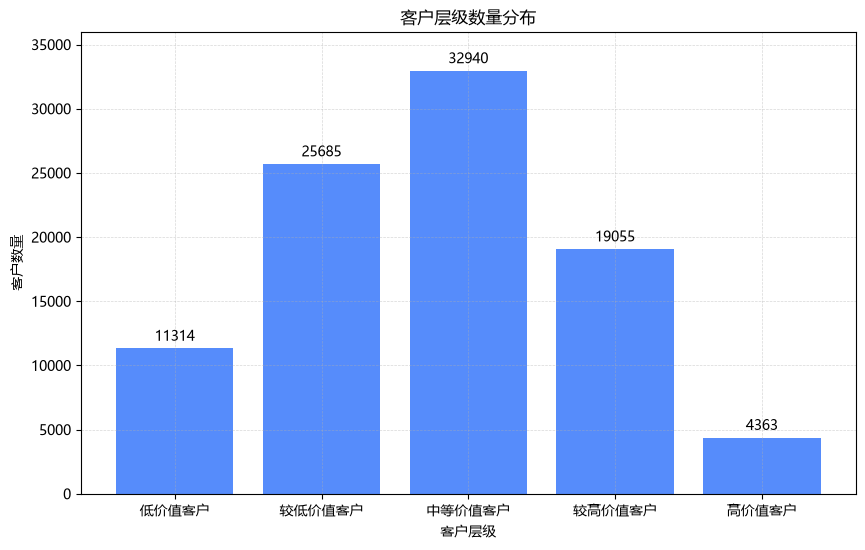

In [54]:
#绘制客户层级柱状图
segment_order =[
    "低价值客户",
    "较低价值客户",
    "中等价值客户",
    "较高价值客户",
    "高价值客户"
]

segment_count =(
    rfm["customer_segment"].value_counts().reindex(segment_order)
)
plt.figure(figsize=(10,6))
bars = plt.bar(
    segment_count.index,
    segment_count.values
)
plt.bar_label(
    bars,
    padding=3
)
plt.title("客户层级数量分布")
plt.grid(axis="both", linestyle="--", linewidth=0.5)
plt.xlabel("客户层级")
plt.ylabel("客户数量")
plt.ylim(0,36000)
plt.yticks(range(0,36001,5000))
plt.show()

In [55]:
segment_revenue = rfm.groupby(
    "customer_segment",
    observed=False
).agg(
    customer_count=("customer_unique_id", "count"),
    total_monetary=("monetary", "sum")
).reset_index()

segment_revenue["revenue_ratio"] = (
    segment_revenue["total_monetary"]
    / segment_revenue["total_monetary"].sum()
)

print(segment_revenue)

  customer_segment  customer_count  total_monetary  revenue_ratio
0           中等价值客户           32940      5882208.53       0.381405
1            低价值客户           11314       572507.65       0.037122
2           较低价值客户           25685      2162011.00       0.140186
3           较高价值客户           19055      4883575.27       0.316653
4            高价值客户            4363      1922159.32       0.124634


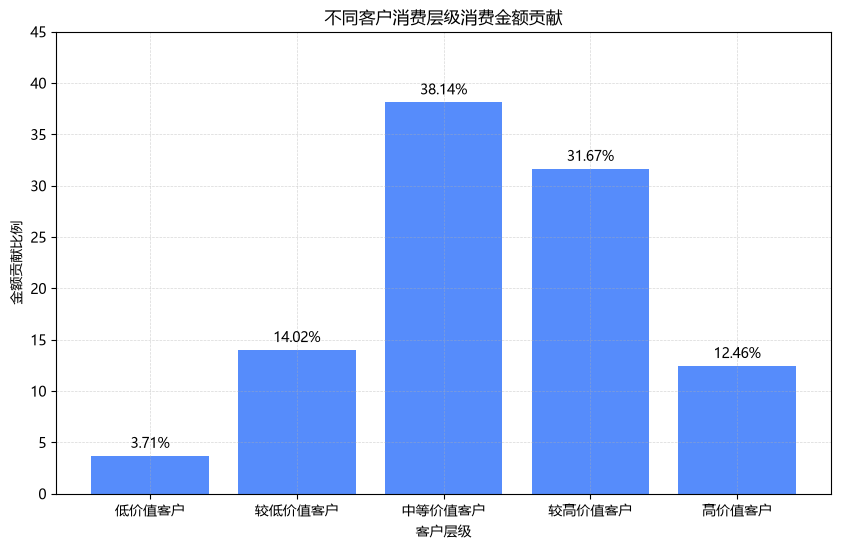

In [56]:
segment_order =[
    "低价值客户",
    "较低价值客户",
    "中等价值客户",
    "较高价值客户",
    "高价值客户"
]
segment_revenue = segment_revenue.set_index(
    "customer_segment"
).reindex(segment_order)

plt.figure(figsize=(10,6))

bars = plt.bar(
    segment_revenue.index,
    segment_revenue["revenue_ratio"] *100
)
plt.bar_label(
    bars,
    fmt= "%.2f%%",
    padding=3
)
plt.title("不同客户消费层级消费金额贡献")
plt.grid(axis="both", linestyle="--", linewidth=0.5)
plt.xlabel("客户层级")
plt.ylabel("金额贡献比例")
plt.ylim(0,45)
plt.show()

In [57]:
#平均值
segment_rfm = rfm.groupby(
    "customer_segment",
    observed=False
).agg(
    avg_recency=("recency", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_monetary=("monetary", "mean")
).reset_index()

segment_rfm = segment_rfm.set_index(
    "customer_segment"
).reindex(segment_order)

print(segment_rfm)

                  avg_recency  avg_frequency  avg_monetary
customer_segment                                          
低价值客户              423.959077       1.000619     50.601701
较低价值客户             305.254740       1.005490     84.174070
中等价值客户             212.842957       1.021038    178.573422
较高价值客户             119.779375       1.060771    256.288390
高价值客户               54.837726       1.256933    440.559092


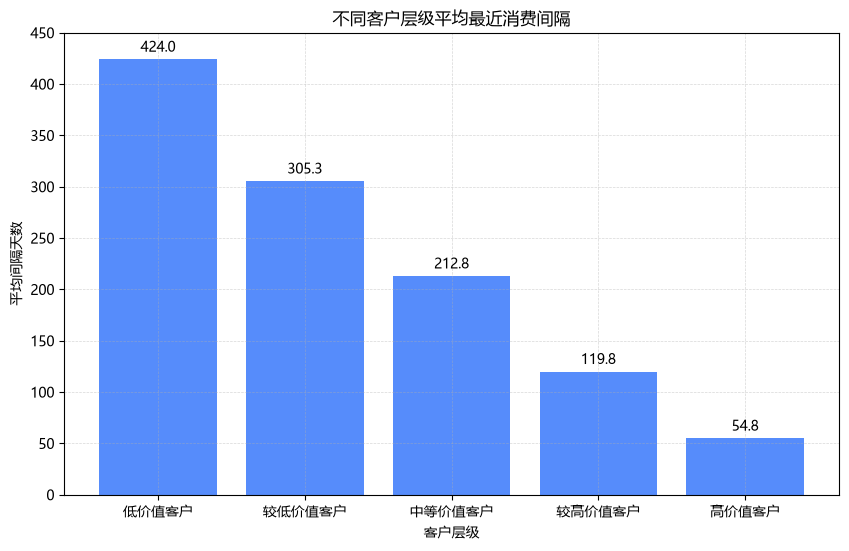

In [58]:
#R值
plt.figure(figsize=(10,6))
bars = plt.bar(
    segment_rfm.index,
    segment_rfm["avg_recency"]
)
plt.bar_label(
    bars,
    fmt= "%.1f",
    padding=3
)
plt.title("不同客户层级平均最近消费间隔")
plt.grid(axis="both", linestyle="--", linewidth=0.5)
plt.xlabel("客户层级")
plt.ylabel("平均间隔天数")
plt.ylim(0,450)
plt.yticks(range(0,451,50))
plt.show()

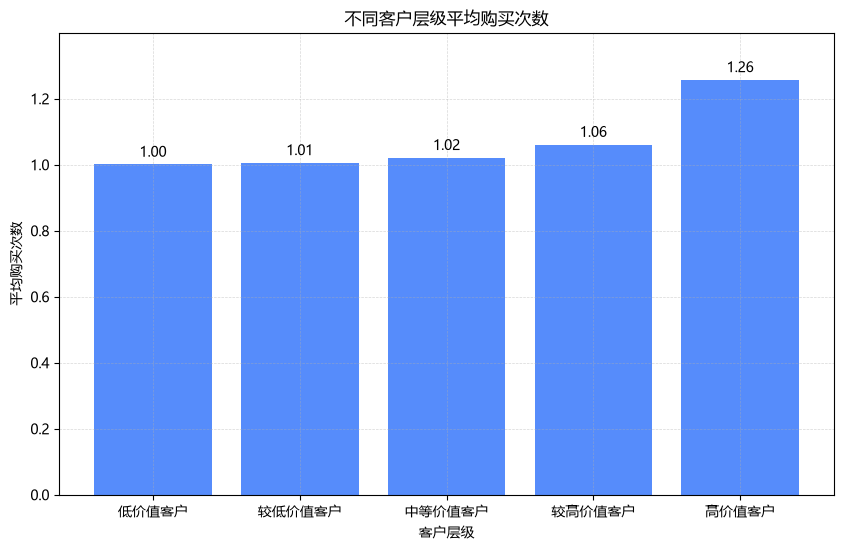

In [59]:
#F指标
plt.figure(figsize=(10,6))
bars = plt.bar(
    segment_rfm.index,
    segment_rfm["avg_frequency"]
)
plt.bar_label(
    bars,
    fmt= "%.2f",
    padding=3
)

plt.title("不同客户层级平均购买次数")
plt.grid(axis="both", linestyle="--", linewidth=0.5)
plt.xlabel("客户层级")
plt.ylabel("平均购买次数")
plt.ylim(0,1.4)
plt.yticks(np.arange(0,1.4,0.2))
plt.show()

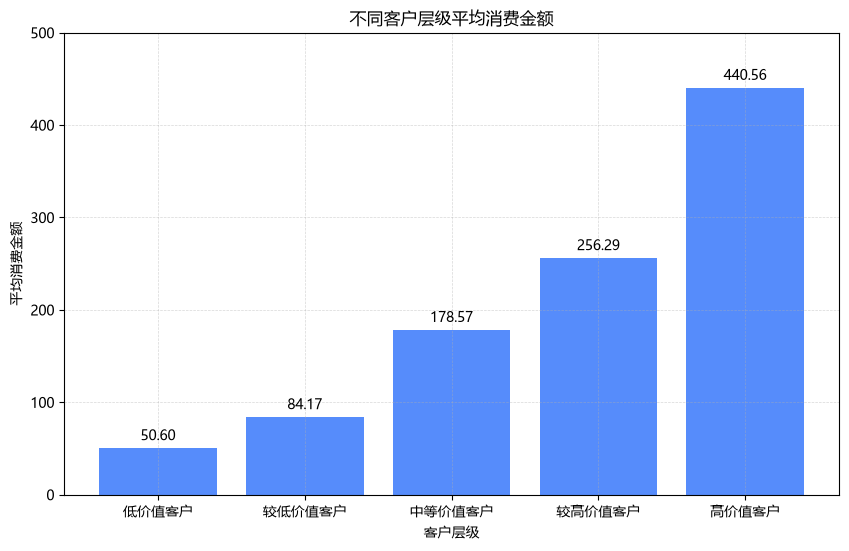

In [60]:
#M指标
plt.figure(figsize=(10,6))
bars = plt.bar(
    segment_rfm.index,
    segment_rfm["avg_monetary"]
)
plt.bar_label(
    bars,
    fmt= "%.2f",
    padding=3
)
plt.title("不同客户层级平均消费金额")
plt.grid(axis="both", linestyle="--", linewidth=0.5)
plt.xlabel("客户层级")
plt.ylabel("平均消费金额")
plt.ylim(0,500)
plt.yticks(np.arange(0,501,100))
plt.show()
plt.show()

In [61]:
#高价值客户的平均消费金额约为低价值客户的平均消费金额的8.7倍，消费金额差距明显

In [62]:
#第二部分，销售趋势可视化
#准备月度订单，在day10中已经分析
#重新计算

In [63]:
orders = pd.read_csv("./data/olist_orders_dataset.csv")

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)
orders["order_purchase_timestamp"]

0       2017-10-02 10:56:33
1       2018-07-24 20:41:37
2       2018-08-08 08:38:49
3       2017-11-18 19:28:06
4       2018-02-13 21:18:39
                ...        
99436   2017-03-09 09:54:05
99437   2018-02-06 12:58:58
99438   2017-08-27 14:46:43
99439   2018-01-08 21:28:27
99440   2018-03-08 20:57:30
Name: order_purchase_timestamp, Length: 99441, dtype: datetime64[us]

In [64]:
#按月份提取订单
orders["order_month"] = (
    orders["order_purchase_timestamp"].dt.to_period("M")
)

monthly_orders = orders.groupby(
    "order_month"
)["order_id"].nunique().reset_index()

monthly_orders.columns = ["order_month", "order_count"]

print(monthly_orders)

   order_month  order_count
0      2016-09            4
1      2016-10          324
2      2016-12            1
3      2017-01          800
4      2017-02         1780
5      2017-03         2682
6      2017-04         2404
7      2017-05         3700
8      2017-06         3245
9      2017-07         4026
10     2017-08         4331
11     2017-09         4285
12     2017-10         4631
13     2017-11         7544
14     2017-12         5673
15     2018-01         7269
16     2018-02         6728
17     2018-03         7211
18     2018-04         6939
19     2018-05         6873
20     2018-06         6167
21     2018-07         6292
22     2018-08         6512
23     2018-09           16
24     2018-10            4


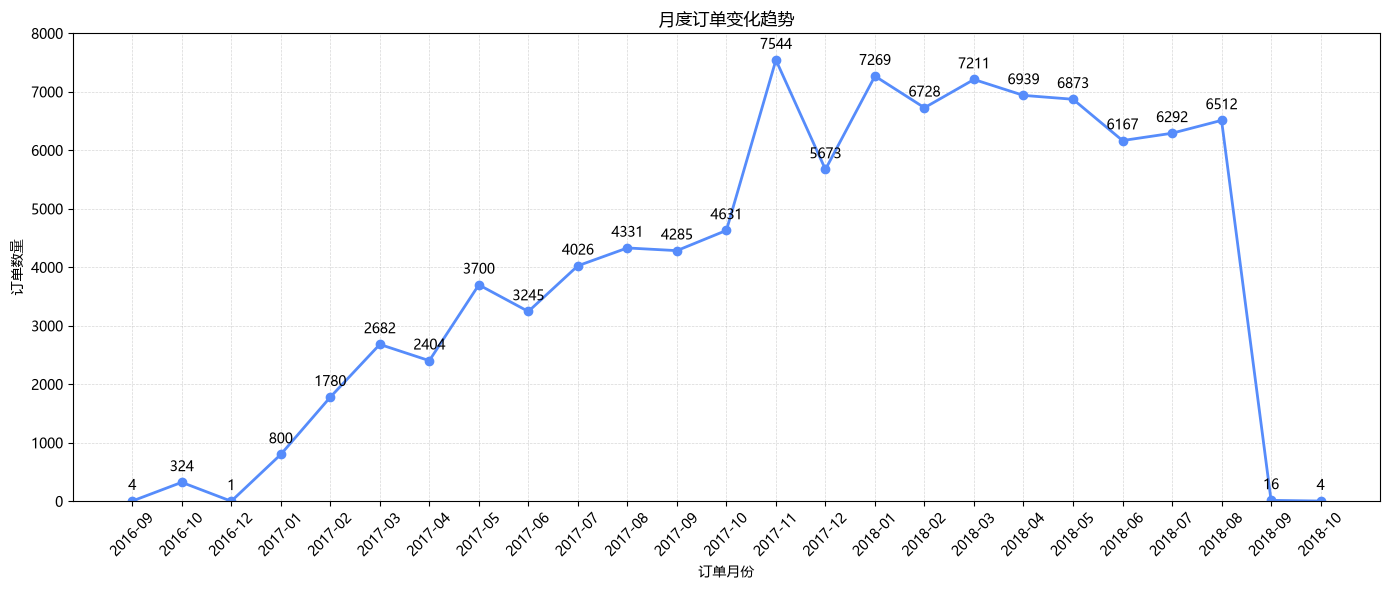

In [65]:
plt.figure(figsize=(14,6))

plt.plot(
    monthly_orders["order_month"].astype(str),
    monthly_orders["order_count"],
    marker="o",
    linewidth=2
)
for x,y in zip(monthly_orders["order_month"].astype(str),monthly_orders["order_count"]):
    plt.annotate(
        y,
        (x, y),
        textcoords="offset points",
        xytext=(0,8),
        ha="center",
    )
plt.title("月度订单变化趋势")
plt.grid(axis="both", linestyle="--", linewidth=0.5)
plt.xlabel("订单月份")
plt.ylabel("订单数量")
plt.ylim(0,8000)
plt.yticks(range(0,8001,1000))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [66]:
#读取支付表
payments = pd.read_csv(
    "./data/olist_order_payments_dataset.csv"
)
print(payments.head())
print(payments.info())

                           order_id  payment_sequential payment_type  \
0  b81ef226f3fe1789b1e8b2acac839d17                   1  credit_card   
1  a9810da82917af2d9aefd1278f1dcfa0                   1  credit_card   
2  25e8ea4e93396b6fa0d3dd708e76c1bd                   1  credit_card   
3  ba78997921bbcdc1373bb41e913ab953                   1  credit_card   
4  42fdf880ba16b47b59251dd489d4441a                   1  credit_card   

   payment_installments  payment_value  
0                     8          99.33  
1                     1          24.39  
2                     1          65.71  
3                     8         107.78  
4                     2         128.45  
<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  str    
 1   payment_sequential    103886 non-null  int64  
 2   payment_t

In [67]:
#按订单汇总总金额
payment_summary = payments.groupby(
    "order_id"
)["payment_value"].sum().reset_index()

print(payment_summary.head())
print("汇总后订单数量：", len(payment_summary))

                           order_id  payment_value
0  00010242fe8c5a6d1ba2dd792cb16214          72.19
1  00018f77f2f0320c557190d7a144bdd3         259.83
2  000229ec398224ef6ca0657da4fc703e         216.87
3  00024acbcdf0a6daa1e931b038114c75          25.78
4  00042b26cf59d7ce69dfabb4e55b4fd9         218.04
汇总后订单数量： 99440


In [68]:
#合并订单月份和金额
monthly_pay =orders[
    ["order_id","order_month"]
].merge(
    payment_summary,
    on="order_id",
    how="left"
)
print(monthly_pay.head())
print(monthly_pay.info())

                           order_id order_month  payment_value
0  e481f51cbdc54678b7cc49136f2d6af7     2017-10          38.71
1  53cdb2fc8bc7dce0b6741e2150273451     2018-07         141.46
2  47770eb9100c2d0c44946d9cf07ec65d     2018-08         179.12
3  949d5b44dbf5de918fe9c16f97b45f8a     2017-11          72.20
4  ad21c59c0840e6cb83a9ceb5573f8159     2018-02          28.62
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype    
---  ------         --------------  -----    
 0   order_id       99441 non-null  str      
 1   order_month    99441 non-null  period[M]
 2   payment_value  99440 non-null  float64  
dtypes: float64(1), period[M](1), str(1)
memory usage: 2.3 MB
None


In [69]:
#统计每个月的销售额
monthly_sales = monthly_pay.groupby(
    "order_month"
)["payment_value"].sum().reset_index()

monthly_sales.columns = [
    "order_month",
    "sales_amount"
]

print(monthly_sales)

   order_month  sales_amount
0      2016-09        252.24
1      2016-10      59090.48
2      2016-12         19.62
3      2017-01     138488.04
4      2017-02     291908.01
5      2017-03     449863.60
6      2017-04     417788.03
7      2017-05     592918.82
8      2017-06     511276.38
9      2017-07     592382.92
10     2017-08     674396.32
11     2017-09     727762.45
12     2017-10     779677.88
13     2017-11    1194882.80
14     2017-12     878401.48
15     2018-01    1115004.18
16     2018-02     992463.34
17     2018-03    1159652.12
18     2018-04    1160785.48
19     2018-05    1153982.15
20     2018-06    1023880.50
21     2018-07    1066540.75
22     2018-08    1022425.32
23     2018-09       4439.54
24     2018-10        589.67


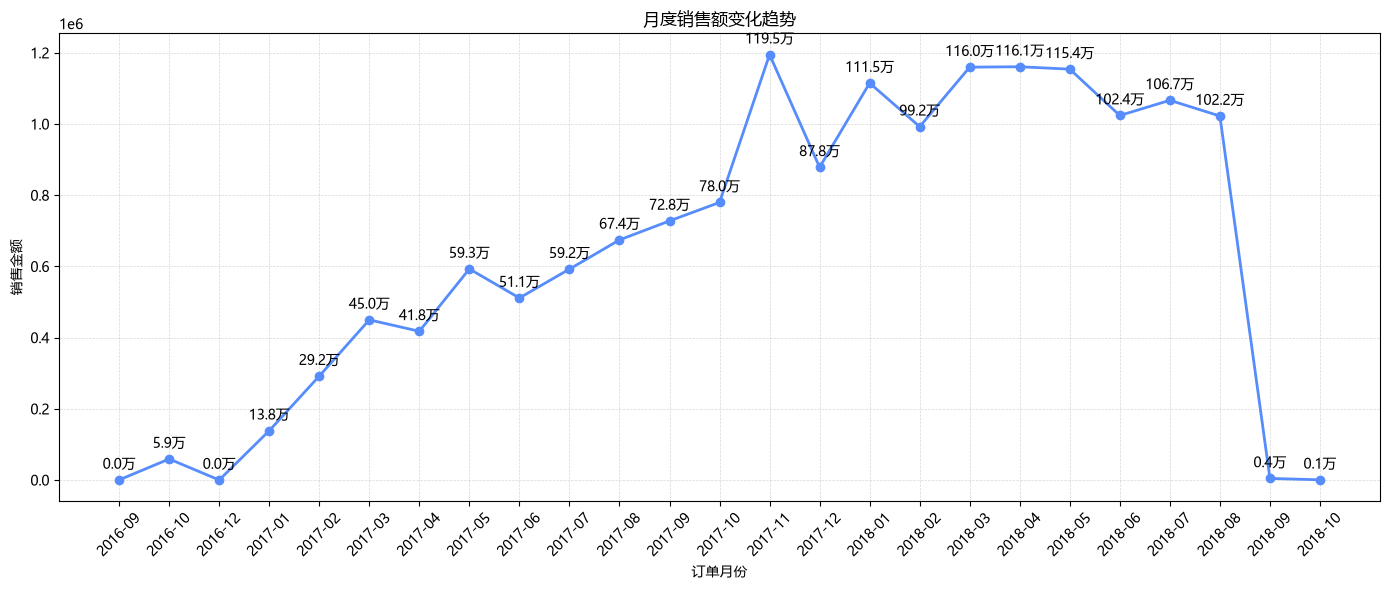

In [70]:
plt.figure(figsize=(14,6))

plt.plot(
    monthly_sales["order_month"].astype(str),
    monthly_sales["sales_amount"],
    marker="o",
    linewidth=2
)
for x,y in zip(
  monthly_sales["order_month"].astype(str),
    monthly_sales["sales_amount"]
):
    plt.annotate(
        f"{y / 10000:.1f}万",
        (x, y),
        textcoords="offset points",
        xytext=(0,8),
        ha="center",
    )
plt.title("月度销售额变化趋势")
plt.grid(axis="both", linestyle="--", linewidth=0.5)
plt.xlabel("订单月份")
plt.ylabel("销售金额")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [71]:
#计算月度AOV
monthly_analysis = monthly_orders.merge(
    monthly_sales,
    on="order_month",
    how="inner"
)

monthly_analysis["AOV"] = (
    monthly_analysis["sales_amount"]
    / monthly_analysis["order_count"]
)

print(monthly_analysis)

   order_month  order_count  sales_amount         AOV
0      2016-09            4        252.24   63.060000
1      2016-10          324      59090.48  182.378025
2      2016-12            1         19.62   19.620000
3      2017-01          800     138488.04  173.110050
4      2017-02         1780     291908.01  163.993264
5      2017-03         2682     449863.60  167.734377
6      2017-04         2404     417788.03  173.788698
7      2017-05         3700     592918.82  160.248330
8      2017-06         3245     511276.38  157.558206
9      2017-07         4026     592382.92  147.139324
10     2017-08         4331     674396.32  155.713766
11     2017-09         4285     727762.45  169.839545
12     2017-10         4631     779677.88  168.360587
13     2017-11         7544    1194882.80  158.388494
14     2017-12         5673     878401.48  154.838971
15     2018-01         7269    1115004.18  153.391688
16     2018-02         6728     992463.34  147.512387
17     2018-03         7211 

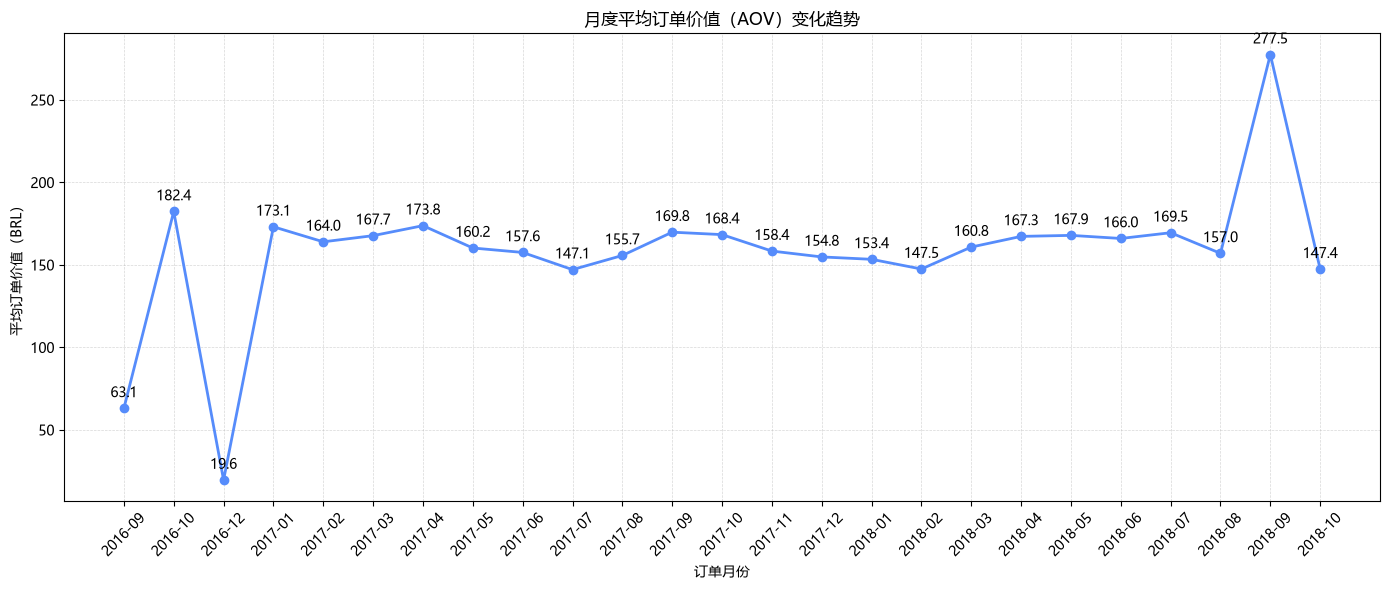

In [72]:
plt.figure(figsize=(14,6))
plt.plot(
    monthly_analysis["order_month"].astype(str),
    monthly_analysis["AOV"],
    marker="o",
    linewidth=2
)
for x,y in zip(
  monthly_analysis["order_month"].astype(str),
    monthly_analysis["AOV"]
):
    plt.annotate(
        f"{y:.1f}",
        (x, y),
        textcoords="offset points",
        xytext=(0,8),
        ha="center",
    )
plt.title("月度平均订单价值（AOV）变化趋势")
plt.xlabel("订单月份")
plt.ylabel("平均订单价值（BRL）")

plt.xticks(rotation=45)
plt.grid(axis="both", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [73]:
#商品类别数据准备
items = pd.read_csv("./data/olist_order_items_dataset.csv")
products = pd.read_csv("./data/olist_products_dataset.csv")
category_translation = pd.read_csv(
    "./data/product_category_name_translation.csv"
)

In [74]:
print(items.head())
print(products.head())
print(category_translation.head())

                           order_id  order_item_id  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   
1  00018f77f2f0320c557190d7a144bdd3              1   
2  000229ec398224ef6ca0657da4fc703e              1   
3  00024acbcdf0a6daa1e931b038114c75              1   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87   

   shipping_limit_date   price  freight_value  
0  2017-09-19 09:45:35   58.90          13.29  
1  2017-05-03 11:05:13  239.90          19.93  
2  2018-01-18 14:48:30  199.00          17.87  
3  2018-08-15 10:10:18   12.99          12.7

In [75]:
#合并商品表
items_products = items.merge(
    products[["product_id","product_category_name"]],
    on="product_id",
    how="left"
)
print("合并前行数：", len(items))
print("合并后行数：", len(items_products))
print("商品类别缺失数：", items_products["product_category_name"].isna().sum())

合并前行数： 112650
合并后行数： 112650
商品类别缺失数： 1603


In [76]:
#检查缺失商品
missing_products = items_products[
    items_products["product_category_name"].isna()
]
print("缺失类别商品明细数",len(missing_products))
print("涉及商品数量",missing_products["product_id"].nunique())
print("缺失商品类别的商品ID示例")
print(missing_products["product_id"].head())

缺失类别商品明细数 1603
涉及商品数量 610
缺失商品类别的商品ID示例
123    ff6caf9340512b8bf6d2a2a6df032cfa
125    a9c404971d1a5b1cbc2e4070e02731fd
132    5a848e4ab52fd5445cdc07aab1c40e48
142    41eee23c25f7a574dfaf8d5c151dbb12
171    e10758160da97891c2fdcbc35f0f031d
Name: product_id, dtype: str


In [77]:
#610种商品对应1603条明细
#检查610种商品是否存在products表中
missing_product_ids = missing_products["product_id"].unique()
print("缺失类别商品是否存在于商品表")
print(
    pd.Series(missing_product_ids).isin(
        products["product_id"]
    ).value_counts()
)
print(
    "商品表总商品数：",
    len(products)
)

print(
    "商品类别缺失数：",
    products["product_category_name"].isna().sum()
)

print(
    products[
        products["product_category_name"].isna()
    ][["product_id", "product_category_name"]].head(10)
)

缺失类别商品是否存在于商品表
True    610
Name: count, dtype: int64
商品表总商品数： 32951
商品类别缺失数： 610
                           product_id product_category_name
105  a41e356c76fab66334f36de622ecbd3a                   NaN
128  d8dee61c2034d6d075997acef1870e9b                   NaN
145  56139431d72cd51f19eb9f7dae4d1617                   NaN
154  46b48281eb6d663ced748f324108c733                   NaN
197  5fb61f482620cb672f5e586bb132eae9                   NaN
244  e10758160da97891c2fdcbc35f0f031d                   NaN
294  39e3b9b12cd0bf8ee681bbc1c130feb5                   NaN
299  794de06c32a626a5692ff50e4985d36f                   NaN
347  7af3e2da474486a3519b0cba9dea8ad9                   NaN
428  629beb8e7317703dcc5f35b5463fd20e                   NaN


In [78]:
#判断为商品表本身的信息不完整
items_products["product_category_name"] = (
    items_products["product_category_name"].fillna("未知类别")
)

In [79]:
print(
    "类别缺失数：",
    items_products["product_category_name"].isna().sum()
)

类别缺失数： 0


In [80]:
#合并英文类别
items_products = items_products.merge(
    category_translation,#葡萄牙语和英语对照表
    on="product_category_name",
    how="left"
)

In [81]:
items_products["product_category_name_english"] = (
    items_products["product_category_name_english"].fillna("unknown")#由于之前的缺失类型，所有将该类型补充为unknown
)
print("合并后行数", len(items_products))
print(
    "英文类别缺失数",
    items_products["product_category_name_english"].isna().sum()
)

合并后行数 112650
英文类别缺失数 0


In [82]:
#按商品类别汇总销售额
category_sales = items_products.groupby(
    "product_category_name_english"
).agg(
    sales_amount=("price", "sum"),
    sales_volume=("order_item_id", "count")
).reset_index()
print(category_sales.head())

  product_category_name_english  sales_amount  sales_volume
0    agro_industry_and_commerce      72530.47           212
1              air_conditioning      55024.96           297
2                           art      24202.64           209
3         arts_and_craftmanship       1814.01            24
4                         audio      50688.50           364


In [83]:
#排列高到低
category_sales = category_sales.sort_values(
    by = "sales_amount",
    ascending = False
).reset_index(drop=True)
print(category_sales.head())

  product_category_name_english  sales_amount  sales_volume
0                 health_beauty    1258681.34          9670
1                 watches_gifts    1205005.68          5991
2                bed_bath_table    1036988.68         11115
3                sports_leisure     988048.97          8641
4         computers_accessories     911954.32          7827


In [84]:
#销售额最高的类别不一定销售量最高

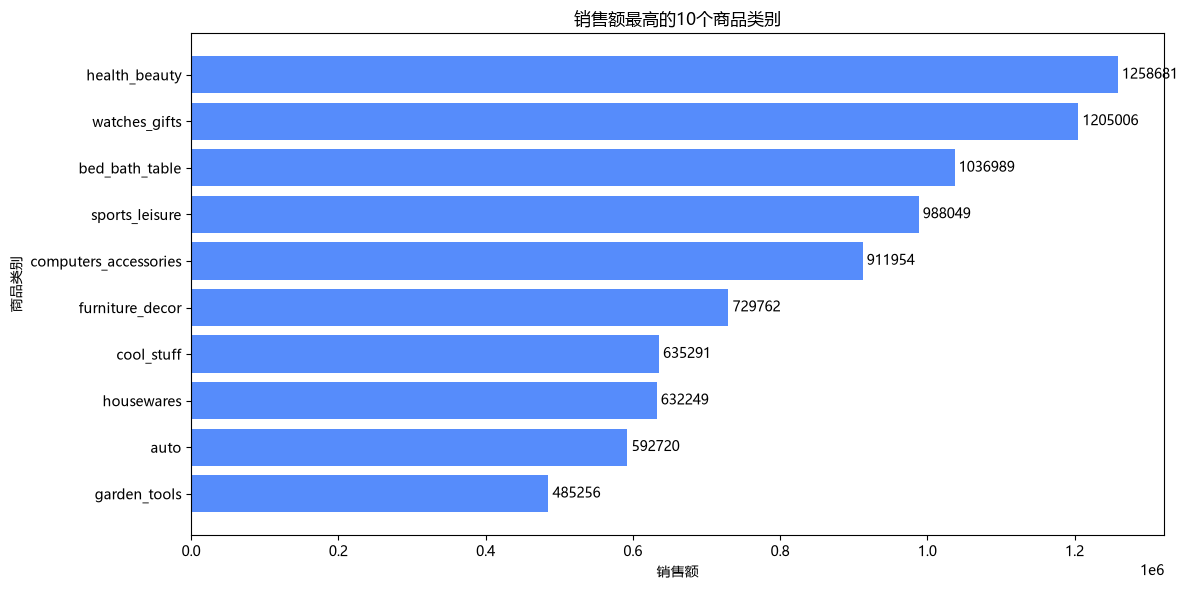

In [85]:
#绘制销售额前10的商品类别图
top_category = category_sales.head(10).sort_values(
    by = "sales_amount",
    ascending = True
)
plt.figure(figsize=(12,6))

bars = plt.barh(
    top_category["product_category_name_english"],
    top_category["sales_amount"]
)
plt.bar_label(bars,fmt="%.0f",padding=3)
plt.title("销售额最高的10个商品类别")
plt.xlabel("销售额")
plt.ylabel("商品类别")
plt.tight_layout()
plt.show()

In [86]:
#结合之前的数据分析，可知销售额和销量排名并不一致，例如bed销售额在1036989，但销量才11115；又比如watches，销售额在1205006，但销量在5991；
#2.前五的销售额都在90w以上，但是第十才48w，头部和尾部存在一定的差距
#至少认为可以重点维护health，可以关注watches，结合销售量bed需要关注库存

In [87]:
#物流数据可视化
#准备物流配送数据
#转换物流相关日期
date_columns = [
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])
#筛选已送达订单
delivery_data = orders[orders["order_status"]=="delivered"].copy()
#计算配送时长
delivery_data["delivery_day"] = (
    delivery_data["order_delivered_customer_date"]
    -delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400
print(delivery_data["delivery_day"].describe())

count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: delivery_day, dtype: float64


In [88]:
#平均配送时长是12.56天，中位数是10.22天

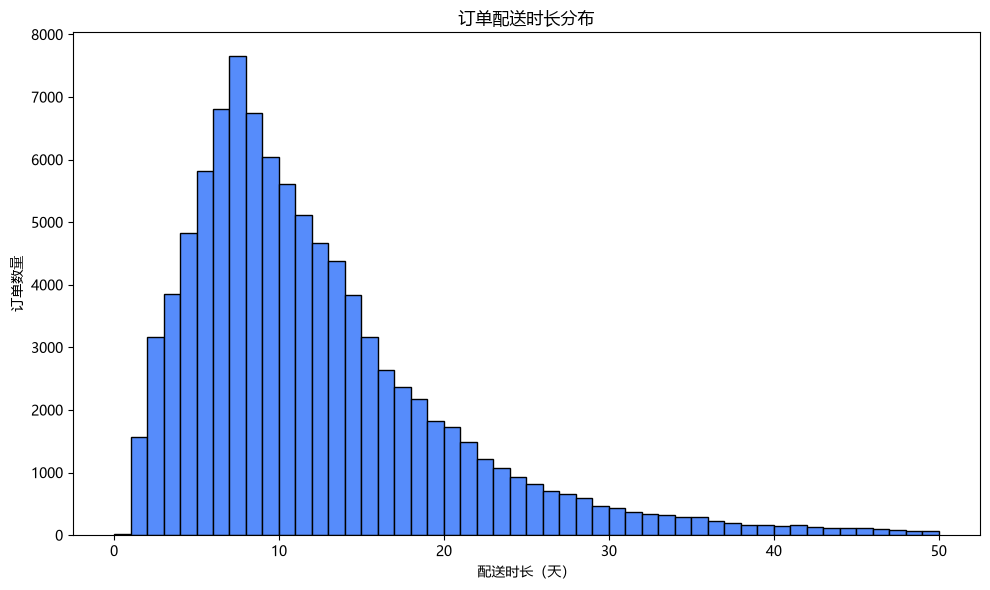

In [89]:
#绘制配送时长分布表
plt.figure(figsize=(10,6))

plt.hist(
    delivery_data["delivery_day"],
    bins = 50,
    range = (0,50),
    edgecolor = "black"
)
plt.title("订单配送时长分布")
plt.xlabel("配送时长（天）")
plt.ylabel("订单数量")
plt.tight_layout()
plt.show()

In [90]:
#1.主要集中在7~10天，在8天最大
#2.配送时间越长订单越少
#3.存在长尾现象
#分析订单是否延迟
delivery_data["is_delayed"] = (
    delivery_data["order_delivered_customer_date"]
    > delivery_data["order_estimated_delivery_date"]
)
delay_count = delivery_data["is_delayed"].value_counts()
print(delay_count)

is_delayed
False    88652
True      7826
Name: count, dtype: int64


In [91]:
#之前记录为96470笔订单，但现在为96478笔，可能是缺失日期比较时统计为False
#统计缺失记录
print(
    delivery_data[[
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]].isna().sum()
)

order_delivered_customer_date    8
order_estimated_delivery_date    0
dtype: int64


In [92]:
# 只保留两个日期都完整的订单
#dropna()删除缺失值
valid_delivery_data = delivery_data.dropna(
    subset=[
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
).copy()

# 重新判断是否延迟
valid_delivery_data["is_delayed"] = (
    valid_delivery_data["order_delivered_customer_date"]
    > valid_delivery_data["order_estimated_delivery_date"]
)

# 计算延迟率
delay_rate = valid_delivery_data["is_delayed"].mean()

print("有效订单数：", len(valid_delivery_data))
print("延迟订单数：", valid_delivery_data["is_delayed"].sum())
print("延迟率：", f"{delay_rate:.2%}")
print("准时或提前送达率：", f"{1-delay_rate:.2%}")

有效订单数： 96470
延迟订单数： 7826
延迟率： 8.11%
准时或提前送达率： 91.89%


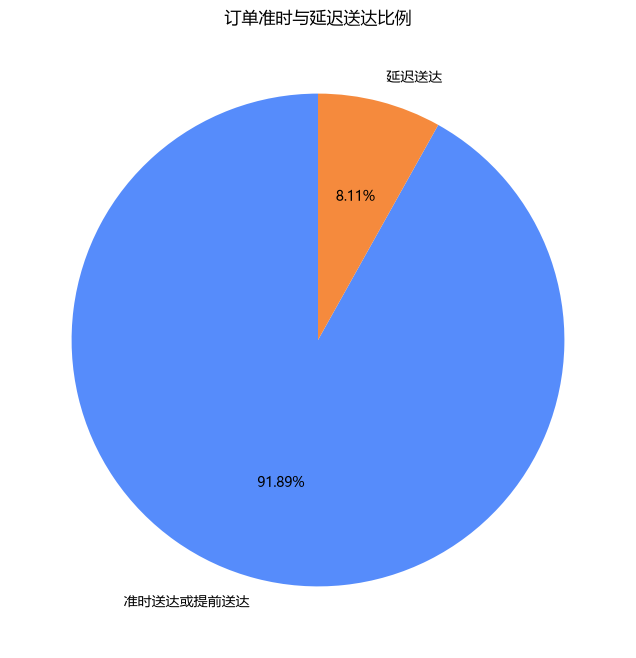

In [93]:
#绘制饼图
delay_count = valid_delivery_data["is_delayed"].value_counts()

plt.figure(figsize=(8,8))

plt.pie(
    delay_count.values,
    labels=["准时送达或提前送达","延迟送达"],
    autopct="%.2f%%",
    startangle=90
)
plt.title("订单准时与延迟送达比例")
plt.show()

## 七、分析结论

### 1. 客户价值分析

通过 RFM 模型对客户进行分层，可以发现不同客户群体的消费价值存在明显差异。其中，较高价值客户与高价值客户合计占客户总数的 25.08%，却贡献了 44.13% 的客户消费金额。

这说明平台的消费金额主要由一部分高价值客户贡献，后续可以重点关注这部分客户的维护与复购，同时通过营销活动提升其他客户的消费价值。

### 2. 月度销售趋势分析

通过月度销售趋势分析，可以观察平台在不同月份的销售表现，识别销售额的增长、下降及波动情况，为了解平台经营趋势和制定后续运营策略提供参考。

### 3. 商品类别销售分析

通过商品类别销售额分析，可以发现不同商品类别的销售表现存在明显差异。销售额排名靠前的商品类别贡献了平台较大比例的销售收入，其中前十类商品约占商品总销售额的 63.20%。

这说明平台销售收入主要集中在部分商品类别，后续可以重点关注优势类别，同时结合市场需求优化其他类别的商品布局。

### 4. 物流配送与延迟率分析

通过物流配送分析，可以了解订单从发货到送达所需的时间，并评估平台的履约表现。分析发现，已送达订单的延迟率约为 8.11%，说明大部分订单能够按时送达，但仍有一部分订单存在配送延迟。

平台后续可以重点关注物流配送环节，分析延迟订单的原因，优化物流合作与配送管理，提升客户购物体验。

### 5. 综合分析总结

本次数据可视化项目从客户价值、月度销售趋势、商品类别销售以及物流配送等多个角度，对 Olist 巴西电商平台的经营情况进行了分析。

分析结果表明，平台存在较明显的客户价值差异，销售收入主要集中在部分商品类别，同时整体物流履约表现较好，但仍存在一定比例的配送延迟。

通过本次分析，能够更加直观地了解平台的经营状况，并为客户维护、商品运营和物流管理提供数据参考。